#**Aula 1: Explorando e vetorizando dados textuais**

##**Conhecendo os dados**

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/alura-cursos/nlp_analise_sentimento/refs/heads/main/Dados/dataset_avaliacoes.csv')

In [3]:
df.head()

,ID_avaliacao,avaliacao,nota,sentimento
0,81841,"Esse smartphone superou minhas expectativas, r...",5,positivo
1,28031,o cheiro e muito desagradavel!! pra quem se in...,2,negativo
2,91332,"Eu fiz a compra a loja nÃ£o entregou o produto,...",1,negativo
3,110045,"Atendeu minhas expectativas, sÃ³ achei a luz ru...",4,positivo
4,36929,"Gostei muito, sÃ³ achei que ficou a desejar a q...",5,positivo


In [4]:
df.shape

(15501, 4)

In [5]:
df.value_counts('sentimento')

sentimento
positivo    7890
negativo    7611
Name: count, dtype: int64

In [6]:
print('positiva \n')

df.avaliacao[0]

positiva 



'Esse smartphone superou minhas expectativas, recomendo'

In [7]:
print('negativa \n')

df.avaliacao[2]

negativa 



'Eu fiz a compra a loja nÃ£o entregou o produto, a compra foi feita no cartÃ£o de credito e ate o momento a loja tambÃ©m nao me devolveu o valor da compra.'

##**Transformando textos em dados numÃ©ricos**

In [8]:
from sklearn.feature_extraction.text import CountVectorizer

texto = ['Comprei um produto Ã³timo', 'Comprei um produto ruim']

vetorizar = CountVectorizer()
bag_of_words = vetorizar.fit_transform(texto)

In [9]:
bag_of_words

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 8 stored elements and shape (2, 5)>

In [10]:
matriz_esparsa = pd.DataFrame.sparse.from_spmatrix(bag_of_words, columns=vetorizar.get_feature_names_out())

In [11]:
matriz_esparsa

,comprei,produto,ruim,um,Ã³timo
0,1,1,0,1,1
1,1,1,1,1,0


In [12]:
vetorizar = CountVectorizer(lowercase=False)
bag_of_words = vetorizar.fit_transform(df.avaliacao)
print(bag_of_words.shape)

(15501, 23352)


In [13]:
vetorizar = CountVectorizer(lowercase=False, max_features=50)
bag_of_words = vetorizar.fit_transform(df.avaliacao)
print(bag_of_words.shape)

(15501, 50)

In [14]:
matriz_esparsa_avaliacoes = pd.DataFrame.sparse.from_spmatrix(bag_of_words, columns=vetorizar.get_feature_names_out())
matriz_esparsa_avaliacoes

,NÃ£o,Produto,ainda,antes,as,atÃ©,bem,bom,chegou,com,...,qualidade,que,recebi,recomendo,se,sem,tem,um,uma,veio
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,1,0,0,0,...,1,2,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15496,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
15497,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,1,0,0,0
15498,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
15499,0,1,0,1,0,0,0,1,1,0,...,0,0,0,0,0,0,0,0,0,0


##**Classificando os sentimentos**

In [15]:
from sklearn.model_selection import train_test_split

X_treino, X_teste, y_treino, y_teste = train_test_split(bag_of_words, df.sentimento, random_state=4978)

In [16]:
from sklearn.linear_model import LogisticRegression

regressao_logistica = LogisticRegression()
regressao_logistica.fit(X_treino, y_treino)
acuracia = regressao_logistica.score(X_teste, y_teste)
print(acuracia)

0.7982456140350878


#**Aula 2: Explorando a frequÃªncia e o sentimento das palavras**

##**Visualizando as palavras mais frequentes nas avaliaÃ§Ãµes**

In [17]:
from wordcloud import WordCloud

In [18]:
todas_palavras = [texto for texto in df.avaliacao]

In [19]:
todas_palavras

['Esse smartphone superou minhas expectativas, recomendo',
 'o cheiro e muito desagradavel!! pra quem se incomoda  nao recomendoo..',
 'Eu fiz a compra a loja nÃ£o entregou o produto, a compra foi feita no cartÃ£o de credito e ate o momento a loja tambÃ©m nao me devolveu o valor da compra.',
 'Atendeu minhas expectativas, sÃ³ achei a luz ruim, mas nada que dificulte seu funcionamento.',
 'Gostei muito, sÃ³ achei que ficou a desejar a qualidade das fotos. Achei que fosse bem melhor .',
 'Comprei o produto e Ã± tinha para entrega isso nÃ£o foi legal!!!!!!',
 'o produto pode atÃ© ser bom ,mais sÃ³ posso avalia-lo depois que for feito a troca para eu usa-lo, pois estou esperando a troca ser feita o que recebi veio quebrado',
 'jÃ¡ enviei duas reclamaÃ§Ãµes, mas nÃ£o obtive resposta. recebi o produto quebrado e quero que seja enviado outro. estou no aguardo para saber o que fazer. att. CÃ¡rmen',
 'nao recebi o produto, pois voces nao cumpriram o compromisso firmado de entregar ate hoje 23/0

In [20]:
todas_palavras = ' '.join([texto for texto in df.avaliacao])

In [21]:
todas_palavras

'Esse smartphone superou minhas expectativas, recomendo o cheiro e muito desagradavel!! pra quem se incomoda  nao recomendoo.. Eu fiz a compra a loja nÃ£o entregou o produto, a compra foi feita no cartÃ£o de credito e ate o momento a loja tambÃ©m nao me devolveu o valor da compra. Atendeu minhas expectativas, sÃ³ achei a luz ruim, mas nada que dificulte seu funcionamento. Gostei muito, sÃ³ achei que ficou a desejar a qualidade das fotos. Achei que fosse bem melhor . Comprei o produto e Ã± tinha para entrega isso nÃ£o foi legal!!!!!! o produto pode atÃ© ser bom ,mais sÃ³ posso avalia-lo depois que for feito a troca para eu usa-lo, pois estou esperando a troca ser feita o que recebi veio quebrado jÃ¡ enviei duas reclamaÃ§Ãµes, mas nÃ£o obtive resposta. recebi o produto quebrado e quero que seja enviado outro. estou no aguardo para saber o que fazer. att. CÃ¡rmen nao recebi o produto, pois voces nao cumpriram o compromisso firmado de entregar ate hoje 23/05/18. PESSIMA LOGISTICA. Ja solic

In [22]:
nuvem_palavras = WordCloud().generate(todas_palavras)

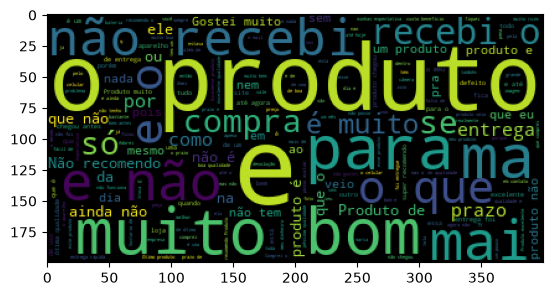

In [23]:
import matplotlib.pyplot as plt

plt.figure()
plt.imshow(nuvem_palavras)
plt.show()

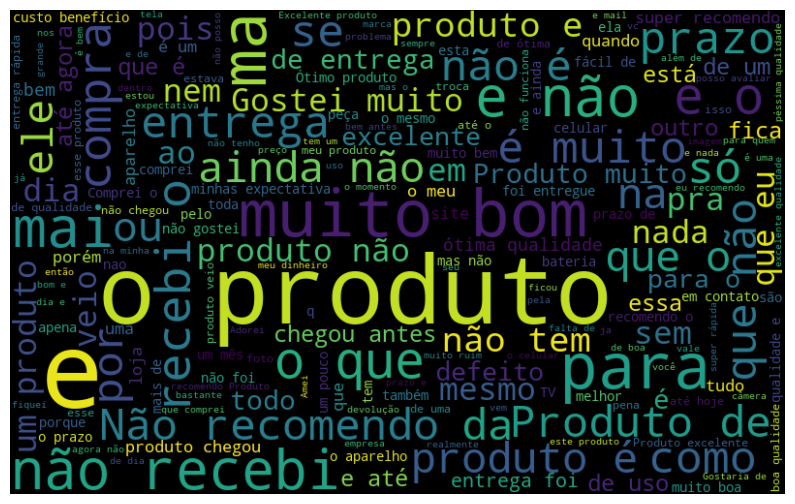

In [24]:
nuvem_palavras = WordCloud(width=800, height=500, max_font_size=110).generate(todas_palavras)
plt.figure(figsize=(10,7))
plt.imshow(nuvem_palavras, interpolation='bilinear')
plt.axis('off')
plt.show()

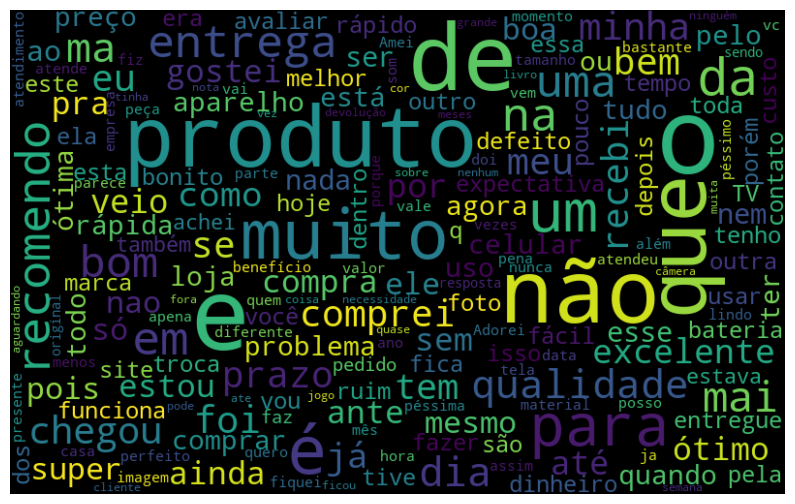

In [25]:
nuvem_palavras = WordCloud(width=800, height=500, max_font_size=110, collocations=False).generate(todas_palavras)
plt.figure(figsize=(10,7))
plt.imshow(nuvem_palavras, interpolation='bilinear')
plt.axis('off')
plt.show()

##**Analisando palavras por sentimento**

In [26]:
def nuvem_palavras(texto, coluna_texto, sentimento):
  # Filtrando as resenhas com base no sentimento especificado
  texto_sentimento = texto.query(f"sentimento == '{sentimento}'")[coluna_texto]

  # Unindo todas as resenhas em uma Ãºnica string
  texto_unido = ' '.join(texto_sentimento)

  # Criando e exibindo a nuvem de palavras
  nuvem_palavras = WordCloud(width=800, height=500, max_font_size=110, collocations=False).generate(texto_unido)
  plt.figure(figsize=(10,7))
  plt.imshow(nuvem_palavras, interpolation='bilinear')
  plt.axis('off')
  plt.show()

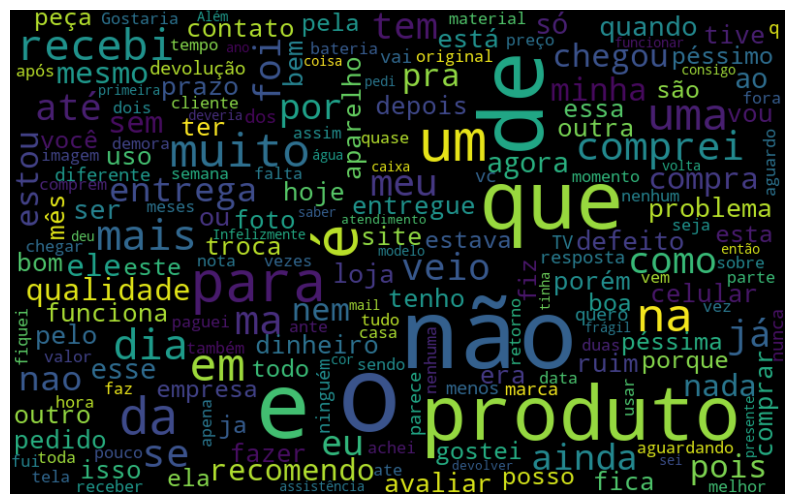

In [27]:
nuvem_palavras(df, 'avaliacao', 'negativo')

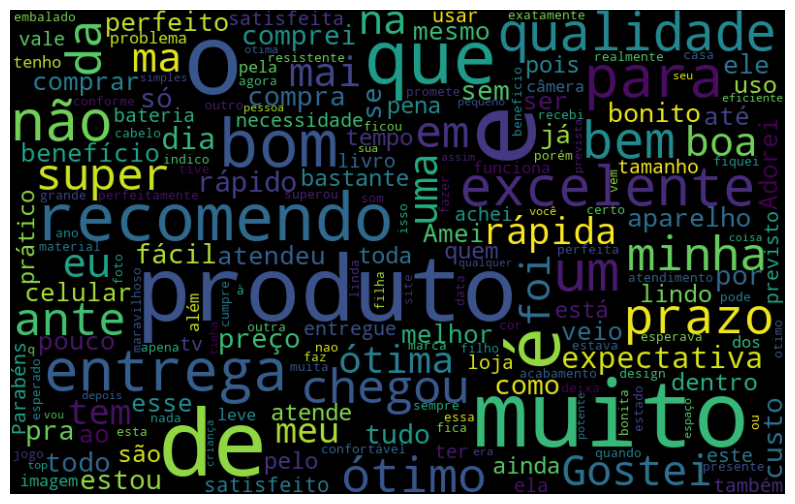

In [28]:
nuvem_palavras(df, 'avaliacao', 'positivo')

##**Dividindo o texto em unidades menores**

In [29]:
todas_palavras

'Esse smartphone superou minhas expectativas, recomendo o cheiro e muito desagradavel!! pra quem se incomoda  nao recomendoo.. Eu fiz a compra a loja nÃ£o entregou o produto, a compra foi feita no cartÃ£o de credito e ate o momento a loja tambÃ©m nao me devolveu o valor da compra. Atendeu minhas expectativas, sÃ³ achei a luz ruim, mas nada que dificulte seu funcionamento. Gostei muito, sÃ³ achei que ficou a desejar a qualidade das fotos. Achei que fosse bem melhor . Comprei o produto e Ã± tinha para entrega isso nÃ£o foi legal!!!!!! o produto pode atÃ© ser bom ,mais sÃ³ posso avalia-lo depois que for feito a troca para eu usa-lo, pois estou esperando a troca ser feita o que recebi veio quebrado jÃ¡ enviei duas reclamaÃ§Ãµes, mas nÃ£o obtive resposta. recebi o produto quebrado e quero que seja enviado outro. estou no aguardo para saber o que fazer. att. CÃ¡rmen nao recebi o produto, pois voces nao cumpriram o compromisso firmado de entregar ate hoje 23/05/18. PESSIMA LOGISTICA. Ja solic

In [ ]:
import nltk

nltk.download("all")

In [31]:
frases = ['um produto bom', 'um produto ruim']
frequencia = nltk.FreqDist(frases)
frequencia

FreqDist({'um produto bom': 1, 'um produto ruim': 1})

In [32]:
from nltk import tokenize

frase = 'O produto Ã© excelente e a entrega foi muito rÃ¡pida!'

token_espaco = tokenize.WhitespaceTokenizer()
token_frase = token_espaco.tokenize(frase)
print(token_frase)

['O', 'produto', 'Ã©', 'excelente', 'e', 'a', 'entrega', 'foi', 'muito', 'rÃ¡pida!']


##**Analisando a frequÃªncia das palavras**

In [33]:
token_frase = token_espaco.tokenize(todas_palavras)

In [34]:
token_frase

['Esse',
 'smartphone',
 'superou',
 'minhas',
 'expectativas,',
 'recomendo',
 'o',
 'cheiro',
 'e',
 'muito',
 'desagradavel!!',
 'pra',
 'quem',
 'se',
 'incomoda',
 'nao',
 'recomendoo..',
 'Eu',
 'fiz',
 'a',
 'compra',
 'a',
 'loja',
 'nÃ£o',
 'entregou',
 'o',
 'produto,',
 'a',
 'compra',
 'foi',
 'feita',
 'no',
 'cartÃ£o',
 'de',
 'credito',
 'e',
 'ate',
 'o',
 'momento',
 'a',
 'loja',
 'tambÃ©m',
 'nao',
 'me',
 'devolveu',
 'o',
 'valor',
 'da',
 'compra.',
 'Atendeu',
 'minhas',
 'expectativas,',
 'sÃ³',
 'achei',
 'a',
 'luz',
 'ruim,',
 'mas',
 'nada',
 'que',
 'dificulte',
 'seu',
 'funcionamento.',
 'Gostei',
 'muito,',
 'sÃ³',
 'achei',
 'que',
 'ficou',
 'a',
 'desejar',
 'a',
 'qualidade',
 'das',
 'fotos.',
 'Achei',
 'que',
 'fosse',
 'bem',
 'melhor',
 '.',
 'Comprei',
 'o',
 'produto',
 'e',
 'Ã±',
 'tinha',
 'para',
 'entrega',
 'isso',
 'nÃ£o',
 'foi',
 'legal!!!!!!',
 'o',
 'produto',
 'pode',
 'atÃ©',
 'ser',
 'bom',
 ',mais',
 'sÃ³',
 'posso',
 'avalia-lo

In [35]:
frequencia = nltk.FreqDist(token_frase)
frequencia

FreqDist({'e': 11813, 'o': 10865, 'de': 10280, 'a': 8873, 'que': 7657, 'nÃ£o': 7286, 'Ã©': 4786, 'produto': 4765, 'com': 4641, 'do': 4583, ...})

In [36]:
df_frequencia = pd.DataFrame({'Palavra': list(frequencia.keys()),
                              'FrequÃªncia': list(frequencia.values())})

In [37]:
df_frequencia.head()

,Palavra,FrequÃªncia
0,Esse,101
1,smartphone,33
2,superou,90
3,minhas,533
4,"expectativas,",79


In [38]:
df_frequencia.nlargest(columns='FrequÃªncia', n=10)

,Palavra,FrequÃªncia
8,e,11813
6,o,10865
29,de,10280
19,a,8873
46,que,7657
22,nÃ£o,7286
163,Ã©,4786
63,produto,4765
177,com,4641
130,do,4583


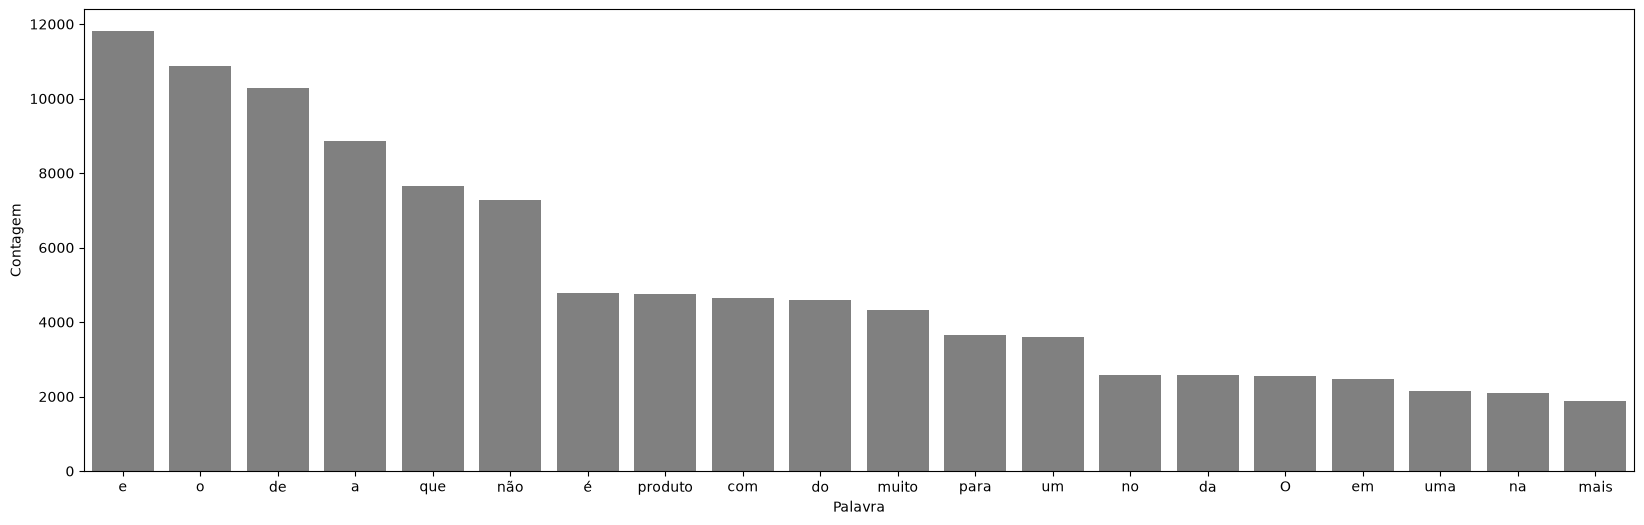

In [39]:
import seaborn as sns

plt.figure(figsize=(20,6))
ax = sns.barplot(data=df_frequencia.nlargest(columns='FrequÃªncia', n=20), x='Palavra', y='FrequÃªncia', color='gray')
ax.set(ylabel='Contagem')
plt.show()

#**Aula 3: Limpando e normalizando dados textuais**

##**Removendo stopwords**

In [40]:
palavras_irrelevantes = nltk.corpus.stopwords.words('portuguese')

In [41]:
palavras_irrelevantes

['a',
 'Ã ',
 'ao',
 'aos',
 'aquela',
 'aquelas',
 'aquele',
 'aqueles',
 'aquilo',
 'as',
 'Ã s',
 'atÃ©',
 'com',
 'como',
 'da',
 'das',
 'de',
 'dela',
 'delas',
 'dele',
 'deles',
 'depois',
 'do',
 'dos',
 'e',
 'Ã©',
 'ela',
 'elas',
 'ele',
 'eles',
 'em',
 'entre',
 'era',
 'eram',
 'Ã©ramos',
 'essa',
 'essas',
 'esse',
 'esses',
 'esta',
 'estÃ¡',
 'estamos',
 'estÃ£o',
 'estar',
 'estas',
 'estava',
 'estavam',
 'estÃ¡vamos',
 'este',
 'esteja',
 'estejam',
 'estejamos',
 'estes',
 'esteve',
 'estive',
 'estivemos',
 'estiver',
 'estivera',
 'estiveram',
 'estivÃ©ramos',
 'estiverem',
 'estivermos',
 'estivesse',
 'estivessem',
 'estivÃ©ssemos',
 'estou',
 'eu',
 'foi',
 'fomos',
 'for',
 'fora',
 'foram',
 'fÃ´ramos',
 'forem',
 'formos',
 'fosse',
 'fossem',
 'fÃ´ssemos',
 'fui',
 'hÃ¡',
 'haja',
 'hajam',
 'hajamos',
 'hÃ£o',
 'havemos',
 'haver',
 'hei',
 'houve',
 'houvemos',
 'houver',
 'houvera',
 'houverÃ¡',
 'houveram',
 'houvÃ©ramos',
 'houverÃ£o',
 'houverei',
 

In [42]:
frase_processada = []

for opiniao in df.avaliacao:
  palavras_texto = token_espaco.tokenize(opiniao)
  nova_frase = [palavra for palavra in palavras_texto if palavra not in palavras_irrelevantes]
  frase_processada.append(' '.join(nova_frase))

df['tratamento_1'] = frase_processada

In [43]:
df.head()

,ID_avaliacao,avaliacao,nota,sentimento,tratamento_1
0,81841,"Esse smartphone superou minhas expectativas, r...",5,positivo,"Esse smartphone superou expectativas, recomendo"
1,28031,o cheiro e muito desagradavel!! pra quem se in...,2,negativo,cheiro desagradavel!! pra incomoda nao recomen...
2,91332,"Eu fiz a compra a loja nÃ£o entregou o produto,...",1,negativo,"Eu fiz compra loja entregou produto, compra fe..."
3,110045,"Atendeu minhas expectativas, sÃ³ achei a luz ru...",4,positivo,"Atendeu expectativas, achei luz ruim, nada dif..."
4,36929,"Gostei muito, sÃ³ achei que ficou a desejar a q...",5,positivo,"Gostei muito, achei ficou desejar qualidade fo..."


In [44]:
df['avaliacao'][0]

'Esse smartphone superou minhas expectativas, recomendo'

In [45]:
df['tratamento_1'][0]

'Esse smartphone superou expectativas, recomendo'

In [46]:
def classificar_texto(texto, coluna_texto, coluna_classificacao):
    vetorizar = CountVectorizer(lowercase=False, max_features=50)
    bag_of_words = vetorizar.fit_transform(texto[coluna_texto])
    X_treino, X_teste, y_treino, y_teste = train_test_split(bag_of_words, texto[coluna_classificacao], random_state=4978)
    regressao_logistica = LogisticRegression()
    regressao_logistica.fit(X_treino, y_treino)
    acuracia = regressao_logistica.score(X_teste, y_teste)
    return print(f"AcurÃ¡cia do modelo com '{coluna_texto}': {acuracia * 100:.2f}%")

In [47]:
classificar_texto(df, 'tratamento_1', 'sentimento')

AcurÃ¡cia do modelo com 'tratamento_1': 81.09%


In [48]:
def grafico_frequencia(texto, coluna_texto, quantidade):
    todas_palavras = ' '.join([texto for texto in texto[coluna_texto]])
    token_espaco = tokenize.WhitespaceTokenizer()
    frequencia = nltk.FreqDist(token_espaco.tokenize(todas_palavras))
    df_frequencia = pd.DataFrame({"Palavra": list(frequencia.keys()),
                                 "FrequÃªncia": list(frequencia.values())})
    df_frequencia = df_frequencia.nlargest(columns="FrequÃªncia", n=quantidade)
    plt.figure(figsize=(20,6))
    ax = sns.barplot(data=df_frequencia, x="Palavra", y ="FrequÃªncia", color='gray')
    ax.set(ylabel="Contagem")
    plt.show()

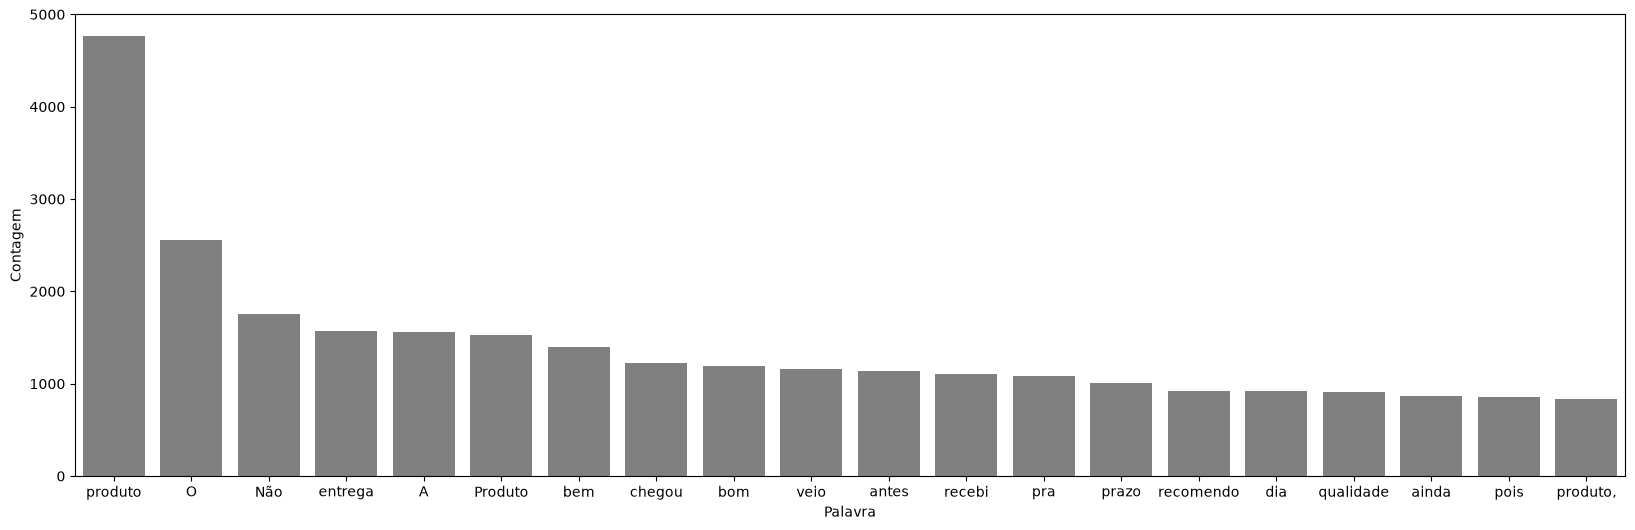

In [49]:
grafico_frequencia(df, 'tratamento_1', 20)

##**Removendo pontuaÃ§Ãµes**

In [50]:
frase = 'Esse smartphone superou expectativas, recomendo'

token_pontuacao = tokenize.WordPunctTokenizer()
token_frase = token_pontuacao.tokenize(frase)
print(token_frase)

['Esse', 'smartphone', 'superou', 'expectativas', ',', 'recomendo']


In [51]:
frase_processada = []

for opiniao in df['tratamento_1']:
  palavras_texto = token_pontuacao.tokenize(opiniao)
  nova_frase = [palavra for palavra in palavras_texto if palavra.isalpha() and palavra not in palavras_irrelevantes]
  frase_processada.append(' '.join(nova_frase))

df['tratamento_2'] = frase_processada

In [52]:
df.head()

,ID_avaliacao,avaliacao,nota,sentimento,tratamento_1,tratamento_2
0,81841,"Esse smartphone superou minhas expectativas, r...",5,positivo,"Esse smartphone superou expectativas, recomendo",Esse smartphone superou expectativas recomendo
1,28031,o cheiro e muito desagradavel!! pra quem se in...,2,negativo,cheiro desagradavel!! pra incomoda nao recomen...,cheiro desagradavel pra incomoda nao recomendoo
2,91332,"Eu fiz a compra a loja nÃ£o entregou o produto,...",1,negativo,"Eu fiz compra loja entregou produto, compra fe...",Eu fiz compra loja entregou produto compra fei...
3,110045,"Atendeu minhas expectativas, sÃ³ achei a luz ru...",4,positivo,"Atendeu expectativas, achei luz ruim, nada dif...",Atendeu expectativas achei luz ruim nada dific...
4,36929,"Gostei muito, sÃ³ achei que ficou a desejar a q...",5,positivo,"Gostei muito, achei ficou desejar qualidade fo...",Gostei achei ficou desejar qualidade fotos Ach...


In [53]:
df['tratamento_1'][10]

'Melhor esperado, cor maravilhosa! Recomendo. Deixa ambiente moderno'

In [54]:
df['tratamento_2'][10]

'Melhor esperado cor maravilhosa Recomendo Deixa ambiente moderno'

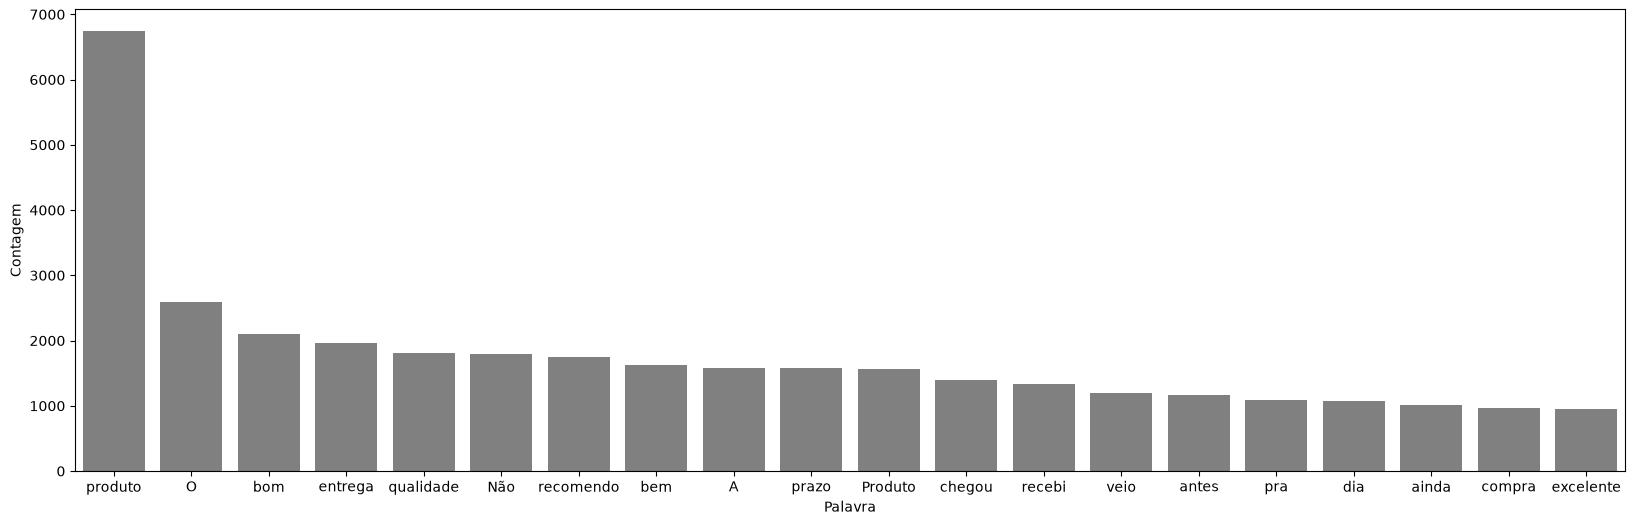

In [55]:
grafico_frequencia(df, 'tratamento_2', 20)

##**Removendo acentuaÃ§Ã£o**

In [56]:
! pip install unidecode


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [57]:
import unidecode

frase =  'Um aparelho Ã³tima performance preÃ§o bem menor outros aparelhos marcas conhecidas performance semelhante'

teste = unidecode.unidecode(frase)
print(teste)

Um aparelho otima performance preco bem menor outros aparelhos marcas conhecidas performance semelhante


In [58]:
sem_acentos = [unidecode.unidecode(texto) for texto in df['tratamento_2']]

In [59]:
stopwords_sem_acento = [unidecode.unidecode(texto) for texto in palavras_irrelevantes]

In [60]:
df['tratamento_3'] = sem_acentos

frase_processada = []

for opiniao in df['tratamento_3']:
  palavras_texto = token_pontuacao.tokenize(opiniao)
  nova_frase = [palavra for palavra in palavras_texto if palavra not in stopwords_sem_acento]
  frase_processada.append(' '.join(nova_frase))

df['tratamento_3'] = frase_processada

In [61]:
df.head()

,ID_avaliacao,avaliacao,nota,sentimento,tratamento_1,tratamento_2,tratamento_3
0,81841,"Esse smartphone superou minhas expectativas, r...",5,positivo,"Esse smartphone superou expectativas, recomendo",Esse smartphone superou expectativas recomendo,Esse smartphone superou expectativas recomendo
1,28031,o cheiro e muito desagradavel!! pra quem se in...,2,negativo,cheiro desagradavel!! pra incomoda nao recomen...,cheiro desagradavel pra incomoda nao recomendoo,cheiro desagradavel pra incomoda recomendoo
2,91332,"Eu fiz a compra a loja nÃ£o entregou o produto,...",1,negativo,"Eu fiz compra loja entregou produto, compra fe...",Eu fiz compra loja entregou produto compra fei...,Eu fiz compra loja entregou produto compra fei...
3,110045,"Atendeu minhas expectativas, sÃ³ achei a luz ru...",4,positivo,"Atendeu expectativas, achei luz ruim, nada dif...",Atendeu expectativas achei luz ruim nada dific...,Atendeu expectativas achei luz ruim nada dific...
4,36929,"Gostei muito, sÃ³ achei que ficou a desejar a q...",5,positivo,"Gostei muito, achei ficou desejar qualidade fo...",Gostei achei ficou desejar qualidade fotos Ach...,Gostei achei ficou desejar qualidade fotos Ach...


In [62]:
df['tratamento_2'][70]

'Melhor compra fiz Ãºltimos tempos Produto barato Ãºtil Produto robusto leve O teclado proporciona digitaÃ§Ã£o confortÃ¡vel mouse preciso O teclado mouse usam apenas receptor economizando nÃºmero portas USB computador Me livrei incomodo fios espaÃ§o trabalho ficou limpo harmonioso Ademais tudo parece bastante durÃ¡vel safisfeito Recomendo todos'

In [63]:
df['tratamento_3'][70]

'Melhor compra fiz ultimos tempos Produto barato util Produto robusto leve O teclado proporciona digitacao confortavel mouse preciso O teclado mouse usam apenas receptor economizando numero portas USB computador Me livrei incomodo fios espaco trabalho ficou limpo harmonioso Ademais tudo parece bastante duravel safisfeito Recomendo todos'

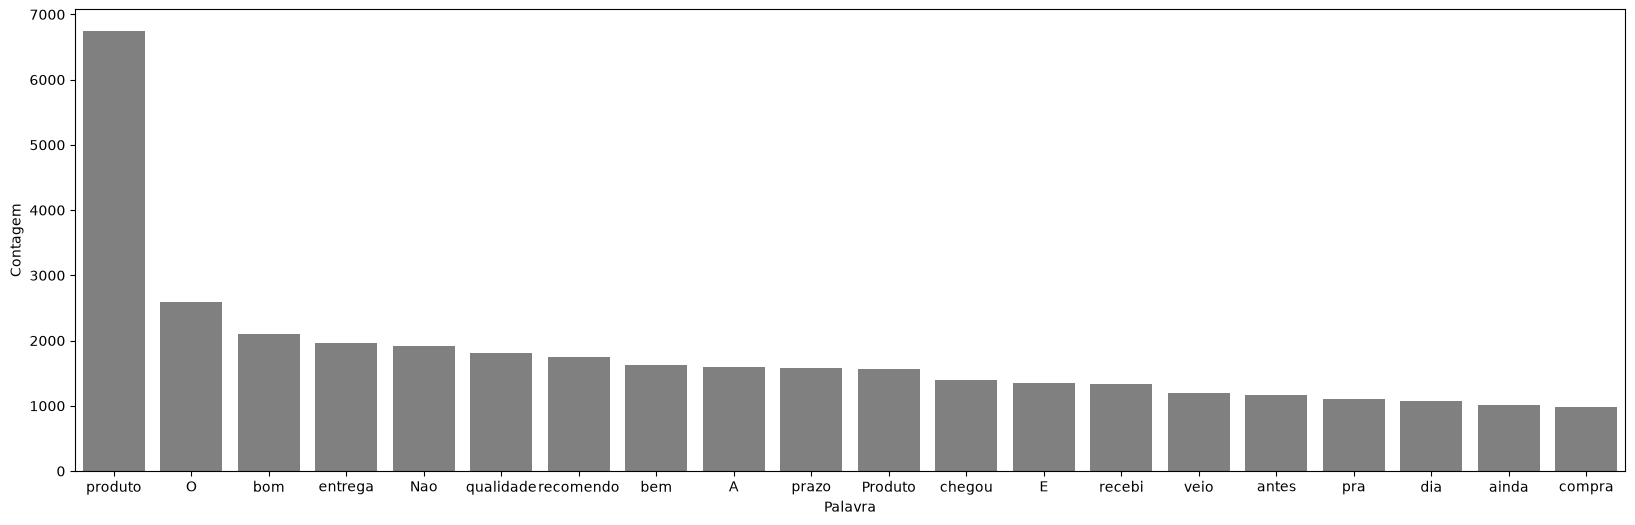

In [64]:
grafico_frequencia(df, 'tratamento_3', 20)

##**Uniformizando o texto**

In [65]:
frase = 'Bom produto otimo custo beneficio Recomendo Confortavel bem acabado'
print(frase.lower())

bom produto otimo custo beneficio recomendo confortavel bem acabado


In [66]:
frase_processada = []

for opiniao in df['tratamento_3']:
  opiniao = opiniao.lower()
  palavras_texto = token_pontuacao.tokenize(opiniao)
  nova_frase = [palavra for palavra in palavras_texto if palavra not in stopwords_sem_acento]
  frase_processada.append(' '.join(nova_frase))

df['tratamento_4'] = frase_processada

In [67]:
df.head()

,ID_avaliacao,avaliacao,nota,sentimento,tratamento_1,tratamento_2,tratamento_3,tratamento_4
0,81841,"Esse smartphone superou minhas expectativas, r...",5,positivo,"Esse smartphone superou expectativas, recomendo",Esse smartphone superou expectativas recomendo,Esse smartphone superou expectativas recomendo,smartphone superou expectativas recomendo
1,28031,o cheiro e muito desagradavel!! pra quem se in...,2,negativo,cheiro desagradavel!! pra incomoda nao recomen...,cheiro desagradavel pra incomoda nao recomendoo,cheiro desagradavel pra incomoda recomendoo,cheiro desagradavel pra incomoda recomendoo
2,91332,"Eu fiz a compra a loja nÃ£o entregou o produto,...",1,negativo,"Eu fiz compra loja entregou produto, compra fe...",Eu fiz compra loja entregou produto compra fei...,Eu fiz compra loja entregou produto compra fei...,fiz compra loja entregou produto compra feita ...
3,110045,"Atendeu minhas expectativas, sÃ³ achei a luz ru...",4,positivo,"Atendeu expectativas, achei luz ruim, nada dif...",Atendeu expectativas achei luz ruim nada dific...,Atendeu expectativas achei luz ruim nada dific...,atendeu expectativas achei luz ruim nada dific...
4,36929,"Gostei muito, sÃ³ achei que ficou a desejar a q...",5,positivo,"Gostei muito, achei ficou desejar qualidade fo...",Gostei achei ficou desejar qualidade fotos Ach...,Gostei achei ficou desejar qualidade fotos Ach...,gostei achei ficou desejar qualidade fotos ach...


In [68]:
df['tratamento_3'][3]

'Atendeu expectativas achei luz ruim nada dificulte funcionamento'

In [69]:
df['tratamento_4'][3]

'atendeu expectativas achei luz ruim nada dificulte funcionamento'

In [70]:
classificar_texto(df, 'tratamento_1', 'sentimento')

AcurÃ¡cia do modelo com 'tratamento_1': 81.09%


In [71]:
classificar_texto(df, 'tratamento_4', 'sentimento')

AcurÃ¡cia do modelo com 'tratamento_4': 83.75%


## Simplificando as palavras

In [72]:
stemmer = nltk.RSLPStemmer()

stemmer.stem('gostei')

'gost'

In [73]:
stemmer.stem('gostado')

'gost'

In [74]:
stemmer.stem('gostou')

'gost'

In [75]:
frase_processada = []
for opinion in df['tratamento_4']:
    palavras_texto = token_pontuacao.tokenize(opinion)
    nova_frase = [stemmer.stem(palavra) for palavra in palavras_texto]
    frase_processada.append(' '.join(nova_frase))

df['tratamento_5'] = frase_processada

In [76]:
df.head()

,ID_avaliacao,avaliacao,nota,sentimento,tratamento_1,tratamento_2,tratamento_3,tratamento_4,tratamento_5
0,81841,"Esse smartphone superou minhas expectativas, r...",5,positivo,"Esse smartphone superou expectativas, recomendo",Esse smartphone superou expectativas recomendo,Esse smartphone superou expectativas recomendo,smartphone superou expectativas recomendo,smartphon super expect recom
1,28031,o cheiro e muito desagradavel!! pra quem se in...,2,negativo,cheiro desagradavel!! pra incomoda nao recomen...,cheiro desagradavel pra incomoda nao recomendoo,cheiro desagradavel pra incomoda recomendoo,cheiro desagradavel pra incomoda recomendoo,cheir desagrada pra incomod recomendo
2,91332,"Eu fiz a compra a loja nÃ£o entregou o produto,...",1,negativo,"Eu fiz compra loja entregou produto, compra fe...",Eu fiz compra loja entregou produto compra fei...,Eu fiz compra loja entregou produto compra fei...,fiz compra loja entregou produto compra feita ...,fiz compr loj entreg produt compr feit carta c...
3,110045,"Atendeu minhas expectativas, sÃ³ achei a luz ru...",4,positivo,"Atendeu expectativas, achei luz ruim, nada dif...",Atendeu expectativas achei luz ruim nada dific...,Atendeu expectativas achei luz ruim nada dific...,atendeu expectativas achei luz ruim nada dific...,atend expect ach luz ruim nad dificult funcion
4,36929,"Gostei muito, sÃ³ achei que ficou a desejar a q...",5,positivo,"Gostei muito, achei ficou desejar qualidade fo...",Gostei achei ficou desejar qualidade fotos Ach...,Gostei achei ficou desejar qualidade fotos Ach...,gostei achei ficou desejar qualidade fotos ach...,gost ach fic desej qual fot ach bem melhor


In [77]:
print(df['tratamento_4'][3])
print(df['tratamento_5'][3])

atendeu expectativas achei luz ruim nada dificulte funcionamento
atend expect ach luz ruim nad dificult funcion


In [78]:
classificar_texto(df, 'tratamento_5', 'sentimento')

AcurÃ¡cia do modelo com 'tratamento_5': 85.11%


## Determinando a importÃ¢ncia das palavras

In [79]:
from sklearn.feature_extraction.text import TfidfVectorizer

frases = ['Comprei um Ã³timo produto', 'Comprei um produto pÃ©ssimo']

tfidf = TfidfVectorizer(lowercase=False, max_features=50)
matriz = tfidf.fit_transform(frases)
pd.DataFrame(matriz.todense(), columns=tfidf.get_feature_names_out())

,Comprei,produto,ssimo,timo,um
0,0.448321,0.448321,0.000000,0.630099,0.448321
1,0.448321,0.448321,0.630099,0.000000,0.448321


### Aplicando TF-IDF no modelo

In [80]:
tfidf_bruto = tfidf.fit_transform(df["avaliacao"])
X_treino, X_teste, y_treino, y_teste = train_test_split(
    tfidf_bruto, df["sentimento"], random_state=4978
)
regressao_logistica.fit(X_treino, y_treino)
acuracia_tfidf_bruto = regressao_logistica.score(X_teste, y_teste)
print(f"AcurÃ¡cia do modelo: {acuracia_tfidf_bruto * 100:.2f}%")

Acur?cia do modelo: 79.54%


In [81]:
tfidf_tratados = tfidf.fit_transform(df['tratamento_5'])
X_treino, X_teste, y_treino, y_teste = train_test_split(
    tfidf_tratados, df['sentimento'], random_state=4978
)
regressao_logistica.fit(X_treino, y_treino)
acuracia_tfidf_tratados = regressao_logistica.score(X_teste, y_teste)
print(f'AcurÃ¡cia do modelo: {acuracia_tfidf_tratados * 100:.2f}%')

Acur?cia do modelo: 85.14%


## Capturando contextos com n-grams

In [82]:
from nltk import ngrams

frase = 'Comprei um produto Ã³timo'
frase_separada = token_espaco.tokenize(frase)
pares = ngrams(frase_separada, 2)
list(pares)

[('Comprei', 'um'), ('um', 'produto'), ('produto', '?timo')]

In [83]:
tfidf_50 = TfidfVectorizer(
    lowercase=False,
    max_features=50,
    ngram_range=(1, 2)
)
vetor_tfidf = tfidf_50.fit_transform(df['tratamento_5'])

X_treino, X_teste, y_treino, y_teste = train_test_split(
    vetor_tfidf,
    df['sentimento'],
    random_state=4978
)

regressao_logistica.fit(X_treino, y_treino)
acuracia_tfidf_ngrams = regressao_logistica.score(X_teste, y_teste)
print(
    f'AcurÃ¡cia do modelo com 50 features e n-grams: '
    f'{acuracia_tfidf_ngrams * 100:.2f}%'
)

Acur?cia do modelo com 50 features e n-grams: 85.22%


In [ ]:
tfidf_100 = TfidfVectorizer(
    lowercase=False,
    max_features=100,
    ngram_range=(1, 2)
)
vetor_tfidf = tfidf_100.fit_transform(df['tratamento_5'])

X_treino, X_teste, y_treino, y_teste = train_test_split(
    vetor_tfidf,
    df['sentimento'],
    random_state=4978
)

regressao_logistica.fit(X_treino, y_treino)
acuracia_tfidf_ngrams = regressao_logistica.score(X_teste, y_teste)
print(
    f'Acurácia do modelo com 100 features e n-grams: '
    f'{acuracia_tfidf_ngrams * 100:.2f}%'
)